## Experiment 1 — Exploratory Data Analysis & Descriptive Statistics
**Dataset:** Housing Dataset (Real-Estate Pricing)  
**Objective:** Explore the structure, distributions, and correlations within the dataset to form initial hypotheses and identify patterns before modelling.  
**Techniques:** Summary statistics, histograms, correlation heatmap, top correlated pairs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Setup & Imports
Load all required libraries for data manipulation, visualisation, and statistical analysis.

In [2]:
df = pd.read_csv("Housing.csv")
print(df.head())

      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


### 2. Load Dataset
Read the CSV file into a pandas DataFrame and preview the first few rows to confirm successful loading and inspect column names.

In [3]:
print("Rows:", df.shape[0], "Columns:", df.shape[1])
print("Columns:", df.columns.tolist())
df.info()
print("Missing values per column:\n", df.isnull().sum())

Rows: 545 Columns: 13
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
mem

### 3. Descriptive Statistics
Compute summary statistics (count, mean, std, min/max, quartiles) for all numerical features. The transposed view improves readability when there are many columns.

In [4]:
numeric_df = df.select_dtypes(include=np.number)
print(numeric_df.describe().T)

           count          mean           std        min        25%        50%  \
price      545.0  4.766729e+06  1.870440e+06  1750000.0  3430000.0  4340000.0   
area       545.0  5.150541e+03  2.170141e+03     1650.0     3600.0     4600.0   
bedrooms   545.0  2.965138e+00  7.380639e-01        1.0        2.0        3.0   
bathrooms  545.0  1.286239e+00  5.024696e-01        1.0        1.0        1.0   
stories    545.0  1.805505e+00  8.674925e-01        1.0        1.0        2.0   
parking    545.0  6.935780e-01  8.615858e-01        0.0        0.0        0.0   

                 75%         max  
price      5740000.0  13300000.0  
area          6360.0     16200.0  
bedrooms         3.0         6.0  
bathrooms        2.0         4.0  
stories          2.0         4.0  
parking          1.0         3.0  


### 4. Distribution Analysis — Histograms
Plot histograms for all numerical variables to visualise their distributions, detect skewness, and identify potential outliers before any modelling step.

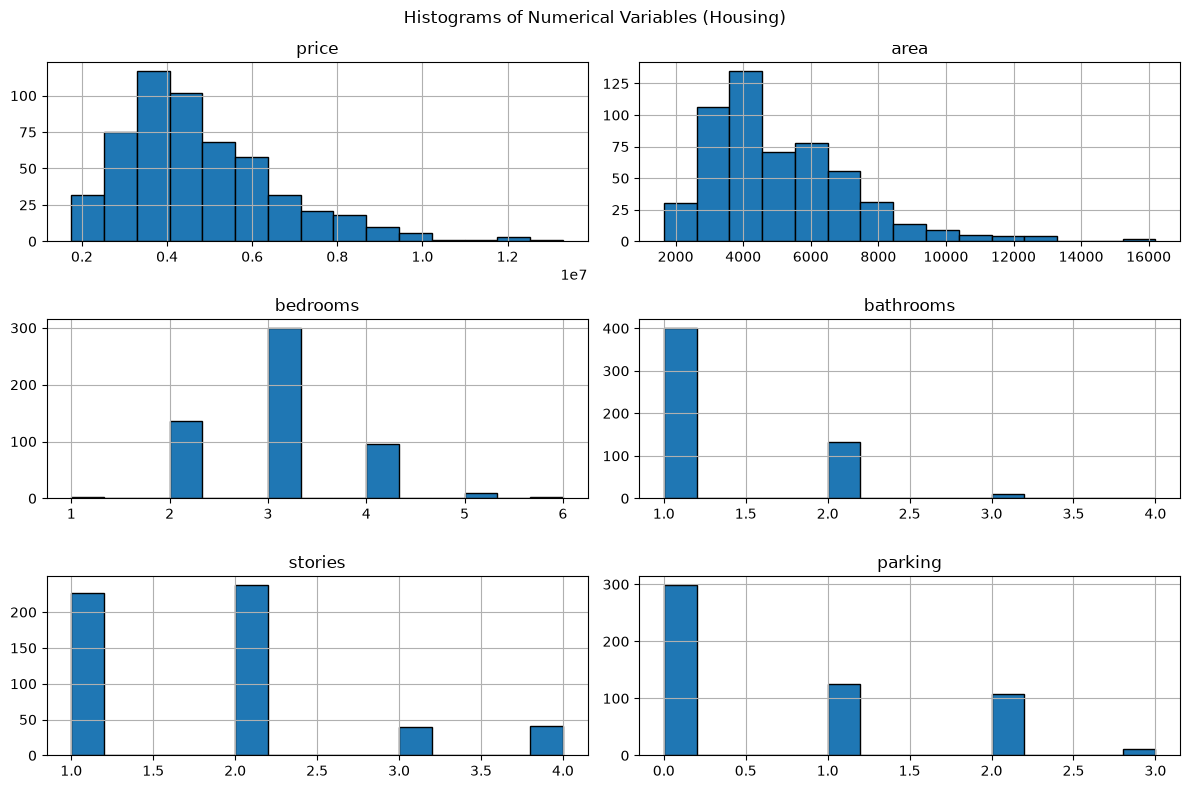

In [5]:
numeric_df.hist(figsize=(12, 8), bins=15, edgecolor="black")
plt.suptitle("Histograms of Numerical Variables (Housing)")
plt.tight_layout()
plt.show()

### 5. Correlation Analysis — Heatmap
Compute the Pearson correlation matrix and render it as an annotated heatmap using a diverging colour palette. High absolute values indicate strong linear relationships between features.

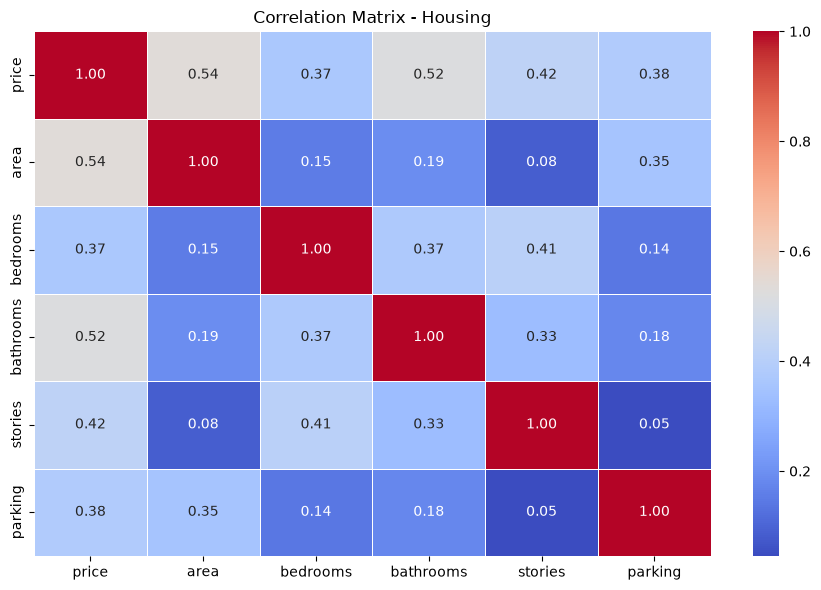

In [6]:
corr = numeric_df.corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix - Housing")
plt.tight_layout()
plt.show()

### 6. Top Correlated Variable Pairs
Extract and rank the upper triangle of the correlation matrix to surface the most strongly correlated feature pairs — useful for feature selection and multicollinearity awareness.

In [7]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack()
print("Top correlated variable pairs:")
print(pairs.sort_values(key=abs, ascending=False).head(10))

Top correlated variable pairs:
price      area         0.535997
           bathrooms    0.517545
           stories      0.420712
bedrooms   stories      0.408564
price      parking      0.384394
bedrooms   bathrooms    0.373930
price      bedrooms     0.366494
area       parking      0.352980
bathrooms  stories      0.326165
area       bathrooms    0.193820
dtype: float64
